# Session 1 · See the data before building a model

**30 October 2026 · Teaching walkthrough · ~60–75 minutes**

Our goal is to reason about image pixels, four independent masks, encoded labels and validation evidence. All arrays here are small, deterministic and synthetic. They teach mechanics; they say nothing about any competition's measured performance.

**Route:** pixels → masks → RLE → defect patterns → geometry → metrics → validation. In each “Predict” prompt, decide before running the next cell. This notebook runs offline on a CPU.

**Setup:** from the repository root, `uv run --no-project --with numpy==2.2.6 --with pandas==2.3.3 --with matplotlib==3.10.9 --with pillow==12.3.0 --with jupyterlab==4.4.9 jupyter lab` to open Jupyter; or run the paired script with the same four pinned packages and `python docs/bootcamp_session_1/foundations_walkthrough.py`. Use the **Python 3** kernel. The runtime needs `numpy`, `pandas`, `matplotlib`, and `Pillow`; no GPU, network or project data is used.

In [1]:
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
np.set_printoptions(linewidth=100)
print('NumPy', np.__version__, '| pandas', pd.__version__)

NumPy 2.2.6 | pandas 2.3.3


## 1 · Pixel values and shape

A grayscale image is an `(H, W)` array; an RGB image is `(H, W, 3)` in **HWC** layout. A model library may ask for `(C, H, W)` instead. The channel axis changes location, not meaning. For ordinary 8-bit images, dividing by 255 maps integer 0…255 to floating 0…1. The right normalization for a trained model depends on its training recipe; today we only inspect the transformation.

**Predict:** What are the shapes and dtype after converting the picture to float? Where does the red pixel land after HWC→CHW?

In [2]:
image = np.array([[[0, 40, 80], [255, 0, 0], [20, 80, 120]],
                  [[90, 90, 90], [0, 255, 0], [255, 255, 255]]], dtype=np.uint8)
image_float = image.astype(np.float32) / 255.0
image_chw = np.transpose(image_float, (2, 0, 1))
print('HWC:', image.shape, image.dtype, '| CHW:', image_chw.shape, image_chw.dtype)
print('red pixel HWC:', image_float[0, 1], '| CHW:', image_chw[:, 0, 1])
assert image_chw.shape == (3, 2, 3)
assert np.allclose(image_chw[:, 0, 1], [1, 0, 0])
assert image_float.min() >= 0 and image_float.max() <= 1

HWC: (2, 3, 3) uint8 | CHW: (3, 2, 3) float32
red pixel HWC: [1. 0. 0.] | CHW: [1. 0. 0.]


## 2 · Four masks share a canvas

Each channel answers a separate yes/no question. A clean pixel has `[0,0,0,0]`; a pixel may in principle have more than one 1. Whether a **particular dataset** actually contains pixel overlap is an observation to verify, not a reason to discard independent labels. Count images with multiple present classes (**co-occurrence**) separately from pixels with multiple classes (**overlap**).

**Predict:** The two masks below occur in one image. Does that imply any pixel is shared?

In [3]:
names = ('Fish', 'Flower', 'Gravel', 'Sugar')  # illustrative cloud-like labels
masks = np.zeros((4, 3, 5), dtype=np.uint8)  # C,H,W
masks[0, 0, 0:2] = 1
masks[1, 2, 3:5] = 1
print('classes present:', [names[i] for i in np.flatnonzero(masks.sum(axis=(1, 2)))])
print('pixels with two or more labels:', int((masks.sum(axis=0) >= 2).sum()))
assert (masks.sum(axis=(1, 2)) > 0).sum() == 2
assert (masks.sum(axis=0) >= 2).sum() == 0
# Make a separate one-pixel overlap to see why the two questions differ.
masks_with_overlap = masks.copy()
masks_with_overlap[1, 0, 0] = 1
assert (masks_with_overlap.sum(axis=0) >= 2).sum() == 1

classes present: ['Fish', 'Flower']
pixels with two or more labels: 0


## 3 · Decode a label with RLE

For this exercise, RLE is a list of **1-based `start length` pairs**. Pixels are visited top to bottom in a column, then the next column: NumPy `order="F"`. A non-square `3×5` mask reveals a wrong traversal order more clearly than a square. The two marked pixels at `(row 1, column 2)` and `(row 2, column 2)` occupy zero-based flat positions `2×3+1=7` and `8`; adding 1 to the first position gives RLE `"8 2"`.

**Predict:** What will `"8 2"` produce if reshaped in default C order?

In [4]:
def decode_rle(rle, shape):
    h, w = shape
    flat = np.zeros(h * w, dtype=np.uint8)
    if pd.isna(rle) or not str(rle).strip():
        return flat.reshape(shape, order='F')
    values = np.asarray(str(rle).split(), dtype=np.int64)
    if values.size % 2:
        raise ValueError('RLE needs start/length pairs')
    previous_end = 0
    for start, length in values.reshape(-1, 2):
        lo, hi = int(start) - 1, int(start) - 1 + int(length)
        if lo < previous_end or length <= 0 or hi > flat.size:
            raise ValueError('RLE runs must be ordered, non-overlapping and in bounds')
        flat[lo:hi] = 1
        previous_end = hi
    return flat.reshape(shape, order='F')

def encode_rle(mask):
    flat = (np.asarray(mask) > 0).astype(np.uint8).reshape(-1, order='F')
    padded = np.r_[0, flat, 0]
    changes = np.flatnonzero(np.diff(padded)) + 1
    changes[1::2] -= changes[::2]
    return ' '.join(map(str, changes))

worked = decode_rle('8 2', (3, 5))
wrong = np.zeros(15, dtype=np.uint8)
wrong[7:9] = 1
wrong = wrong.reshape((3, 5), order='C')
print('correct F order:\n', worked, '\nwrong C order:\n', wrong)
assert worked[1, 2] == worked[2, 2] == 1 and worked.sum() == 2
assert not np.array_equal(worked, wrong)
assert encode_rle(worked) == '8 2'
assert np.array_equal(decode_rle('', (3, 5)), np.zeros((3, 5)))

correct F order:
 [[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]] 
wrong C order:
 [[0 0 0 0 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]


**Try:** Change the mask to contain `(0,0)` and `(2,4)`. Predict the RLE, then call `encode_rle`. Answer after trying: `"1 1 15 1"`. The functions stay filled in so **Run All** is safe. The real lab will check the external dataset's RLE convention before applying this decoder.

## 4 · Geometry and binary masks

An image `90×60` has width:height `1.5:1`. Resizing it to `30×30` changes the apparent object shape. A same-scale `45×30` resize preserves the ratio. Resize continuous image intensity with bilinear interpolation; resize class masks with nearest-neighbor so labels stay exactly 0 or 1. Cropping, padding and tiling each need their own alignment checks.

**Predict:** What extra values might appear in a binary mask if we use bilinear interpolation?

native ratio: 1.5 | preserved ratio: 1.5 | square ratio: 1.0
nearest labels: [False  True] | bilinear edge values: [  0  64 128 255]


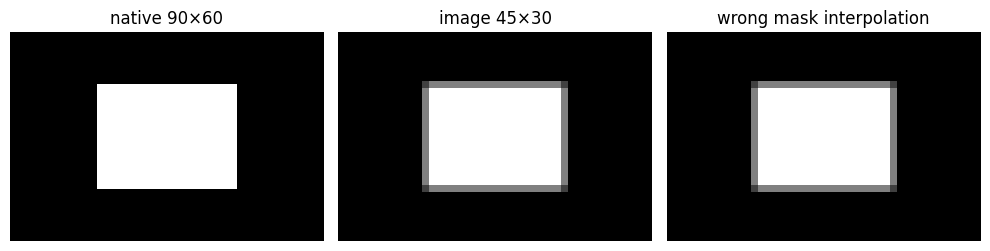

In [5]:
h, w = 60, 90
pattern = np.zeros((h, w), dtype=np.uint8)
pattern[15:45, 25:65] = 255
source_image = Image.fromarray(pattern)
mask_small = Image.fromarray((pattern > 0).astype(np.uint8) * 255)
image_resized = np.asarray(source_image.resize((45, 30), Image.Resampling.BILINEAR))
mask_nearest = np.asarray(mask_small.resize((45, 30), Image.Resampling.NEAREST)) > 0
mask_bilinear = np.asarray(mask_small.resize((45, 30), Image.Resampling.BILINEAR))
print('native ratio:', w/h, '| preserved ratio:', 45/30, '| square ratio:', 30/30)
print('nearest labels:', np.unique(mask_nearest), '| bilinear edge values:', np.unique(mask_bilinear)[:12])
assert set(np.unique(mask_nearest)).issubset({False, True})
assert np.any((mask_bilinear > 0) & (mask_bilinear < 255))
fig, ax = plt.subplots(1, 3, figsize=(10, 2.7))
for a, data, title in zip(ax, [pattern, image_resized, mask_bilinear], ['native 90×60', 'image 45×30', 'wrong mask interpolation']):
    a.imshow(data, cmap='gray', vmin=0, vmax=255); a.set_title(title); a.axis('off')
plt.tight_layout(); plt.show()

## 5 · Count the scarce signal

A label can be rare by **images containing it** and by **pixels belonging to it**. These are distinct denominators. Plot both before choosing sampling or a loss. Here is a deterministic six-image toy collection; one image may contain two categories.

        images_present  image_fraction  positive_pixels  pixel_fraction
Fish                 2        0.333333                4        0.044444
Flower               0        0.000000                0        0.000000
Gravel               2        0.333333                8        0.088889
Sugar                1        0.166667                4        0.044444
clean images: 2 | images with ≥2 classes: 1
overlap pixels: 0


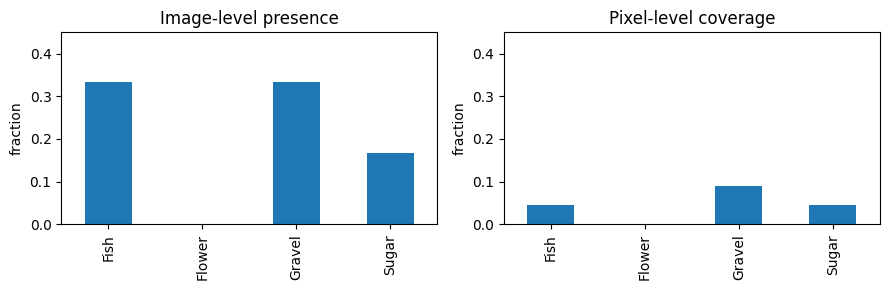

In [6]:
toy = np.zeros((6, 4, 3, 5), dtype=np.uint8)  # N,C,H,W
toy[0, 0, 0, 0:2] = 1
toy[1, 0, 1, 1:3] = 1
toy[1, 2, :, 4] = 1
toy[2, 2, 1, :] = 1
toy[3, 3, 0:2, 0:2] = 1
presence = (toy.sum(axis=(2, 3)) > 0)
image_counts = presence.sum(axis=0)
pixel_counts = toy.sum(axis=(0, 2, 3))
summary = pd.DataFrame({'images_present': image_counts, 'image_fraction': image_counts/len(toy),
                        'positive_pixels': pixel_counts, 'pixel_fraction': pixel_counts/(len(toy)*3*5)}, index=names)
print(summary.to_string())
print('clean images:', int((presence.sum(axis=1)==0).sum()), '| images with ≥2 classes:', int((presence.sum(axis=1)>=2).sum()))
print('overlap pixels:', int((toy.sum(axis=1)>=2).sum()))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
summary.image_fraction.plot.bar(ax=ax[0], title='Image-level presence')
summary.pixel_fraction.plot.bar(ax=ax[1], title='Pixel-level coverage')
for a in ax: a.set_ylim(0, max(.45, a.get_ylim()[1])); a.set_ylabel('fraction')
plt.tight_layout(); plt.show()

## 6 · Hard Dice, empty masks and false alarms

For binary prediction `P` and ground truth `G`, `Dice = 2|P∩G|/(|P|+|G|)`. The formula is undefined if both are empty. We explicitly set empty/empty to 1 and one-empty to 0. This is a **teaching diagnostic**, not the scoring function of a different competition. A lone false positive on an empty target mask changes its per-mask Dice from 1 to 0.

**Predict:** What happens if a three-pixel predicted blob contains two true pixels and one extra pixel?

In [7]:
def hard_dice(prediction, truth):
    p, g = np.asarray(prediction, dtype=bool), np.asarray(truth, dtype=bool)
    if p.shape != g.shape:
        raise ValueError('shapes differ')
    denominator = int(p.sum() + g.sum())
    return 1.0 if denominator == 0 else 2 * int((p & g).sum()) / denominator

truth = np.array([1, 1, 0, 0], dtype=np.uint8)
pred = np.array([1, 1, 1, 0], dtype=np.uint8)
print('2 TP, 1 FP:', hard_dice(pred, truth))
print('both empty:', hard_dice([0,0], [0,0]), '| one false alarm:', hard_dice([1,0], [0,0]))
assert np.isclose(hard_dice(pred, truth), 4/5)
assert hard_dice([0,0], [0,0]) == 1
assert hard_dice([1,0], [0,0]) == 0

2 TP, 1 FP: 0.8
both empty: 1.0 | one false alarm: 0.0


## 7 · Thresholds and minimum area are decisions

A probability-like score needs a threshold to become a hard mask. A small-component filter may remove isolated false alarms but can also remove a true tiny defect. We use one-dimensional connected runs here to make the trade-off visible. Any threshold or minimum area must be chosen using validation data, never hidden test labels or leaderboard feedback.

**Predict:** Will removing one-pixel runs help the clean case? What if the lone pixel is real?

In [8]:
def keep_runs_at_least(mask, minimum):
    a = np.asarray(mask, dtype=bool)
    out = np.zeros_like(a)
    edges = np.flatnonzero(np.diff(np.r_[False, a, False].astype(np.int8)))
    for start, end in edges.reshape(-1, 2):
        if end - start >= minimum:
            out[start:end] = True
    return out

scores = np.array([[.9, .8, .2, .1], [.1, .55, .1, .1], [.1, .55, .1, .1]])
truths = np.array([[1, 1, 0, 0], [0, 0, 0, 0], [0, 1, 0, 0]])
for threshold, minimum in [(.5, 1), (.5, 2), (.7, 1)]:
    hard = np.array([keep_runs_at_least(row >= threshold, minimum) for row in scores])
    print(f'threshold={threshold:.1f}, min run={minimum}:', [hard_dice(p, g) for p,g in zip(hard, truths)])
assert hard_dice(keep_runs_at_least(scores[1]>=.5, 2), truths[1]) == 1
assert hard_dice(keep_runs_at_least(scores[2]>=.5, 2), truths[2]) == 0

threshold=0.5, min run=1: [1.0, 0.0, 1.0]
threshold=0.5, min run=2: [1.0, 1.0, 0.0]
threshold=0.7, min run=1: [1.0, 1.0, 0.0]


## 8 · Split before making derived samples

The unit is the original image (or patient/scene if images share a source). If several crops or flips of one source cross into both train and validation, evaluation leaks. Fix a split using original IDs **before** creating derived images. A fixed seed makes the demonstration repeatable; for real data, inspect whether rare classes are represented and record the split.

**Predict:** Why is a random split of the ten derived rows below invalid?

In [9]:
source_ids = np.array(['scene_A', 'scene_B', 'scene_C', 'scene_D', 'scene_E'])
rng = np.random.default_rng(30)
shuffled = rng.permutation(source_ids)
train_ids, val_ids = set(shuffled[:-2]), set(shuffled[-2:])
derived = [(source, variation) for source in source_ids for variation in ('original', 'flip')]
train_derived = [row for row in derived if row[0] in train_ids]
val_derived = [row for row in derived if row[0] in val_ids]
print('train originals:', sorted(train_ids), '| validation originals:', sorted(val_ids))
print('derived counts:', len(train_derived), len(val_derived))
assert train_ids.isdisjoint(val_ids)
assert {x[0] for x in train_derived}.isdisjoint({x[0] for x in val_derived})

train originals: [np.str_('scene_A'), np.str_('scene_B'), np.str_('scene_E')] | validation originals: [np.str_('scene_C'), np.str_('scene_D')]
derived counts: 6 4


## Exit ticket

1. In `(4, 128, 800)`, which axis names the category? Which numbers describe height and width?
2. An image has Fish and Sugar labels. What additional calculation is needed to assert pixel overlap?
3. What would change if RLE were C-order or 0-based?
4. Why can a clean validation image get Dice 0 after one false-positive pixel?
5. Why do we split before making crops or flips?

**Check yourself:** class axis 0; compute `mask.sum(axis=0)>=2`; wrong spatial coordinates; one-empty convention; related samples otherwise leak. Next, use the real-data lab to test the same ideas on a different public four-class dataset.